In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict
import heapq

PROJECT_DIR = '/content/drive/MyDrive/FAB_AMR_Project'
SIM_DIR     = f'{PROJECT_DIR}/04_simulator'
OUTPUT_DIR  = f'{SIM_DIR}/output'

print("✅ 준비 완료!")

Mounted at /content/drive
✅ 준비 완료!


In [2]:
# grid_map, port_locations, fab_layout 로드
grid_map = np.load(f'{OUTPUT_DIR}/grid_map.npy')

with open(f'{OUTPUT_DIR}/port_locations.json') as f:
    port_locations = json.load(f)

with open(f'{OUTPUT_DIR}/fab_layout.json') as f:
    fab_layout = json.load(f)

grid_h, grid_w = grid_map.shape
meta = fab_layout['meta']

print("로드 완료!")
print(f"  격자 크기:  {grid_w} x {grid_h}")
print(f"  포트 수:    {len(port_locations)}개")
print(f"  이동 가능:  {(grid_map == 0).sum() + (grid_map == 2).sum()}개 셀")

로드 완료!
  격자 크기:  159 x 86
  포트 수:    1116개
  이동 가능:  8984개 셀


In [3]:
#A* 알고리즘 구현
def astar(grid_map, start, goal):
    """
    A* 경로 탐색

    grid_map: 2D numpy array
               0 = 이동 가능
               1 = obstacle (이동 불가)
               2 = 포트 (이동 가능)
    start: (gx, gy) 시작 위치
    goal:  (gx, gy) 목표 위치

    return: 경로 [(gx,gy), ...] 또는 None (경로 없음)
    """

    grid_h, grid_w = grid_map.shape

    def heuristic(a, b):
        """맨해튼 거리"""
        return abs(a[0] - b[0]) + abs(a[1] - b[1])

    def is_valid(x, y):
        """이동 가능한 셀인지 확인"""
        return (0 <= x < grid_w and
                0 <= y < grid_h and
                grid_map[y][x] != 1)  # obstacle 아니면 이동 가능

    # 8방향 이동 (상하좌우 + 대각선)
    directions = [
        (0, 1), (0, -1), (1, 0), (-1, 0),   # 상하좌우
        (1, 1), (1, -1), (-1, 1), (-1, -1)   # 대각선
    ]
    # 대각선 이동 비용은 √2 ≈ 1.414
    dir_costs = [1, 1, 1, 1, 1.414, 1.414, 1.414, 1.414]

    # 시작점 = 목표점
    if start == goal:
        return [start]

    # 시작/목표 유효성 확인
    if not is_valid(start[0], start[1]):
        return None
    if not is_valid(goal[0], goal[1]):
        return None

    # ── A* 메인 ──
    # open_set: (f_cost, g_cost, (x,y))
    open_set = []
    heapq.heappush(open_set, (0, 0, start))

    came_from = {}          # 경로 역추적용
    g_cost = {start: 0}     # 시작점~현재 실제 비용

    while open_set:
        _, current_g, current = heapq.heappop(open_set)

        # 목표 도달
        if current == goal:
            # 경로 역추적
            path = []
            node = goal
            while node in came_from:
                path.append(node)
                node = came_from[node]
            path.append(start)
            path.reverse()
            return path

        # 이미 더 좋은 경로로 처리됨
        if current_g > g_cost.get(current, float('inf')):
            continue

        # 이웃 탐색
        for (dx, dy), cost in zip(directions, dir_costs):
            nx, ny = current[0] + dx, current[1] + dy
            neighbor = (nx, ny)

            if not is_valid(nx, ny):
                continue

            new_g = g_cost[current] + cost

            if new_g < g_cost.get(neighbor, float('inf')):
                g_cost[neighbor] = new_g
                f_cost = new_g + heuristic(neighbor, goal)
                came_from[neighbor] = current
                heapq.heappush(open_set, (f_cost, new_g, neighbor))

    return None  # 경로 없음


print("✅ A* 알고리즘 정의 완료!")

✅ A* 알고리즘 정의 완료!


In [4]:
# 단일 AMR 경로 테스트
# 포트 목록에서 랜덤으로 출발지/목적지 선택
import random
random.seed(42)

port_names = list(port_locations.keys())
start_eqp  = random.choice(port_names)
goal_eqp   = random.choice(port_names)

while goal_eqp == start_eqp:
    goal_eqp = random.choice(port_names)

start_port = port_locations[start_eqp]
goal_port  = port_locations[goal_eqp]

start = (start_port['grid_x'], start_port['grid_y'])
goal  = (goal_port['grid_x'],  goal_port['grid_y'])

print(f"출발: {start_eqp}  grid{start}")
print(f"도착: {goal_eqp}  grid{goal}")
print(f"직선 거리: {abs(start[0]-goal[0]) + abs(start[1]-goal[1])}칸")
print("\nA* 경로 탐색 중...")

import time
t0   = time.time()
path = astar(grid_map, start, goal)
t1   = time.time()

if path:
    print(f"\n✅ 경로 발견!")
    print(f"   경로 길이: {len(path)}칸")
    print(f"   탐색 시간: {(t1-t0)*1000:.1f}ms")
    print(f"   경로 앞부분: {path[:5]}...")
else:
    print("❌ 경로 없음 - 다른 포트 선택 필요")

출발: ECH0179  grid(26, 67)
도착: DIE0144  grid(133, 69)
직선 거리: 109칸

A* 경로 탐색 중...

✅ 경로 발견!
   경로 길이: 111칸
   탐색 시간: 6.4ms
   경로 앞부분: [(26, 67), (26, 68), (27, 69), (28, 70), (29, 71)]...


/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 53456 (\N{HANGUL SYLLABLE TAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 49353 (\N{HANGUL SYLLABLE SAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4267856364.py:72: UserWarning: Glyph 52636 (\N{HANGUL SYLLABLE CUL}) missing from font(s) DejaVu Sans.
  plt.tight_lay

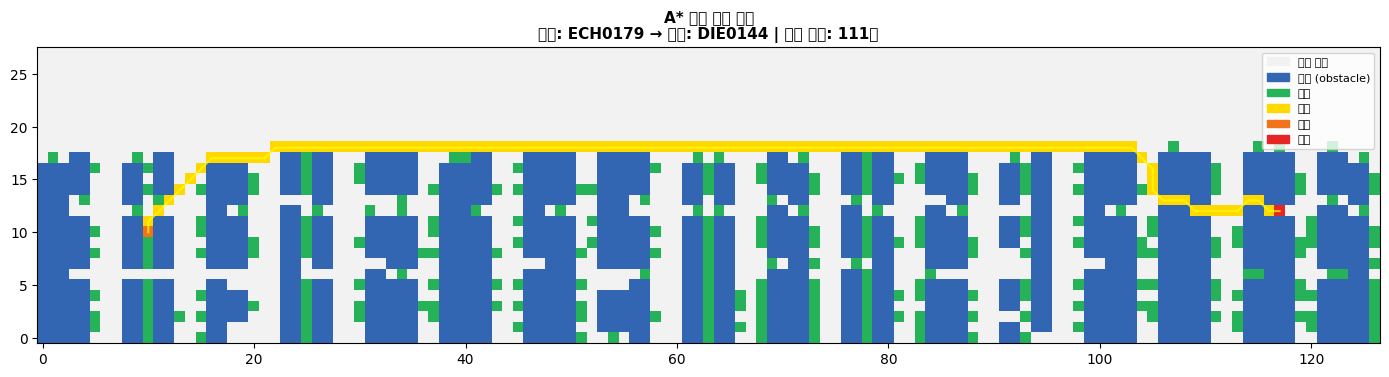

In [5]:
#경로 시각화
def visualize_path(grid_map, path, start, goal,
                   start_name="", goal_name="",
                   zoom=True):
    """단일 AMR 경로 시각화"""

    grid_h, grid_w = grid_map.shape

    color_map_vis = {
        0: [0.95, 0.95, 0.95],  # 이동 가능
        1: [0.20, 0.40, 0.70],  # obstacle
        2: [0.15, 0.70, 0.35],  # 포트
    }

    rgb = np.array([[color_map_vis[int(grid_map[r][c])]
                     for c in range(grid_w)]
                    for r in range(grid_h)], dtype=float)

    # 경로 표시 (노란색)
    if path:
        for (px, py) in path[1:-1]:
            if 0 <= py < grid_h and 0 <= px < grid_w:
                rgb[py][px] = [1.0, 0.85, 0.0]

    # 시작점 (주황), 도착점 (빨강)
    if 0 <= start[1] < grid_h and 0 <= start[0] < grid_w:
        rgb[start[1]][start[0]] = [0.95, 0.45, 0.10]
    if 0 <= goal[1] < grid_h and 0 <= goal[0] < grid_w:
        rgb[goal[1]][goal[0]]   = [0.90, 0.15, 0.15]

    # 확대 범위 계산
    if zoom and path:
        xs = [p[0] for p in path]
        ys = [p[1] for p in path]
        margin = 10
        x1 = max(0, min(xs) - margin)
        x2 = min(grid_w, max(xs) + margin)
        y1 = max(0, min(ys) - margin)
        y2 = min(grid_h, max(ys) + margin)
        rgb_show = rgb[y1:y2, x1:x2]
    else:
        x1, y1 = 0, 0
        rgb_show = rgb

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(rgb_show, origin='lower', aspect='equal')

    # 경로 선
    if path and zoom:
        path_xs = [p[0] - x1 for p in path]
        path_ys = [p[1] - y1 for p in path]
        ax.plot(path_xs, path_ys,
                'yellow', linewidth=1.5, alpha=0.7)

    legend = [
        mpatches.Patch(color=[0.95,0.95,0.95], label='이동 가능'),
        mpatches.Patch(color=[0.20,0.40,0.70], label='장비 (obstacle)'),
        mpatches.Patch(color=[0.15,0.70,0.35], label='포트'),
        mpatches.Patch(color=[1.0,0.85,0.0],   label='경로'),
        mpatches.Patch(color=[0.95,0.45,0.10], label='출발'),
        mpatches.Patch(color=[0.90,0.15,0.15], label='도착'),
    ]
    ax.legend(handles=legend, loc='upper right', fontsize=8)

    length = len(path) if path else 0
    ax.set_title(
        f"A* 경로 탐색 결과\n"
        f"출발: {start_name} → 도착: {goal_name} "
        f"| 경로 길이: {length}칸",
        fontsize=11, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()


visualize_path(
    grid_map, path, start, goal,
    start_name=start_eqp,
    goal_name=goal_eqp,
    zoom=True
)

In [6]:
# AMR 여러 대 경로 테스트
# AMR 5대 동시 경로 탐색 (충돌 무시, 개별 A*)
# → 4단계에서 충돌 처리 추가 예정

N_AMRS = 5
random.seed(99)

requests = []
for i in range(N_AMRS):
    s_name = random.choice(port_names)
    g_name = random.choice(port_names)
    while g_name == s_name:
        g_name = random.choice(port_names)

    s = port_locations[s_name]
    g = port_locations[g_name]
    requests.append({
        "amr_id":     i + 1,
        "start_name": s_name,
        "goal_name":  g_name,
        "start":      (s['grid_x'], s['grid_y']),
        "goal":       (g['grid_x'], g['grid_y']),
    })

print(f"AMR {N_AMRS}대 경로 탐색 중...\n")

paths = []
for req in requests:
    t0   = time.time()
    p    = astar(grid_map, req['start'], req['goal'])
    t1   = time.time()
    paths.append(p)

    status = f"{len(p)}칸" if p else "경로 없음"
    print(f"  AMR {req['amr_id']}: "
          f"{req['start_name'][:15]:15s} → "
          f"{req['goal_name'][:15]:15s} | "
          f"{status} ({(t1-t0)*1000:.0f}ms)")

AMR 5대 경로 탐색 중...

  AMR 1: LITH0245        → LITH0197        | 16칸 (0ms)
  AMR 2: ECH0360         → ECH0317         | 11칸 (0ms)
  AMR 3: ECH0422         → ECH0459         | 17칸 (0ms)
  AMR 4: ECH0223         → ECH0128         | 33칸 (2ms)
  AMR 5: ECH0465         → LITH0202        | 87칸 (12ms)


/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 45796 (\N{HANGUL SYLLABLE DA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_660/4015699315.py:61: UserWarning: Glyph 53456 (\N{HANGUL SYLLABLE TAM}) missing from font(s) DejaVu Sans.
  plt.tight_layo

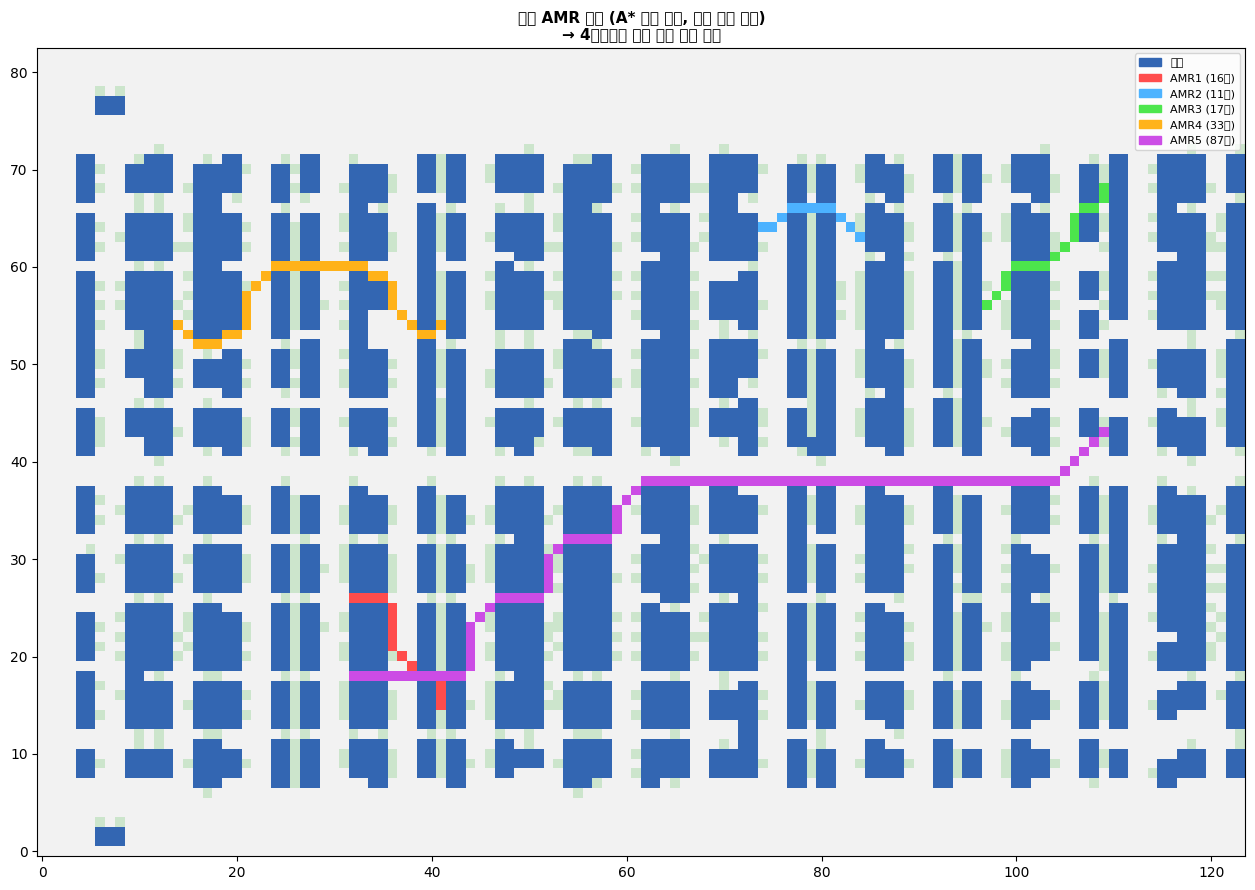

In [7]:
# 다중 AMR 경로 시각화
# AMR 여러 대 경로 한 번에 시각화
amr_colors = [
    [1.0, 0.3, 0.3],   # 빨강
    [0.3, 0.7, 1.0],   # 파랑
    [0.3, 0.9, 0.3],   # 초록
    [1.0, 0.7, 0.1],   # 주황
    [0.8, 0.3, 0.9],   # 보라
]

color_map_vis = {
    0: [0.95, 0.95, 0.95],
    1: [0.20, 0.40, 0.70],
    2: [0.80, 0.90, 0.80],
}

rgb = np.array([[color_map_vis[int(grid_map[r][c])]
                 for c in range(grid_w)]
                for r in range(grid_h)], dtype=float)

# 전체 경로 범위
all_xs, all_ys = [], []
for path in paths:
    if path:
        all_xs += [p[0] for p in path]
        all_ys += [p[1] for p in path]

margin = 15
x1 = max(0, min(all_xs) - margin)
x2 = min(grid_w, max(all_xs) + margin)
y1 = max(0, min(all_ys) - margin)
y2 = min(grid_h, max(all_ys) + margin)

# 각 AMR 경로 색칠
for i, (path, color) in enumerate(zip(paths, amr_colors)):
    if path:
        for (px, py) in path:
            if 0 <= py < grid_h and 0 <= px < grid_w:
                rgb[py][px] = color

rgb_show = rgb[y1:y2, x1:x2]

fig, ax = plt.subplots(figsize=(15, 9))
ax.imshow(rgb_show, origin='lower', aspect='equal')

# 범례
legend = [mpatches.Patch(color=[0.20,0.40,0.70], label='장비')]
for i, (req, color) in enumerate(zip(requests, amr_colors)):
    if paths[i]:
        legend.append(mpatches.Patch(
            color=color,
            label=f"AMR{req['amr_id']} ({len(paths[i])}칸)"
        ))

ax.legend(handles=legend, loc='upper right', fontsize=8)
ax.set_title(
    f"다중 AMR 경로 (A* 개별 탐색, 충돌 처리 없음)\n"
    f"→ 4단계에서 충돌 회피 추가 예정",
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.show()

In [8]:
# 결과 저장
path_result = [
    {
        "amr_id":     req['amr_id'],
        "start":      list(req['start']),
        "goal":       list(req['goal']),
        "start_name": req['start_name'],
        "goal_name":  req['goal_name'],
        "path_length": len(p) if p else 0,
        "path_found":  p is not None,
        "path":        [list(step) for step in p] if p else [],
    }
    for req, p in zip(requests, paths)
]

with open(f'{OUTPUT_DIR}/path_result.json', 'w') as f:
    json.dump(path_result, f, indent=2)

# ── 체크리스트 ──
print("=" * 40)
print("3단계 체크리스트")
print("=" * 40)

checks = [
    ("A* 함수 정의",       callable(astar),              ""),
    ("단일 경로 탐색",     path is not None,
     f"{len(path)}칸" if path else "실패"),
    ("다중 경로 탐색",     any(p for p in paths),
     f"{sum(1 for p in paths if p)}/{N_AMRS}개 성공"),
    ("path_result.json",  os.path.exists(
        f'{OUTPUT_DIR}/path_result.json'), ""),
]

for name, result, detail in checks:
    status = "✅" if result else "❌"
    detail_str = f"  ({detail})" if detail else ""
    print(f"  {status} {name}{detail_str}")

print()
if all(r for _, r, _ in checks):
    print("🎉 3단계 완료! 4단계 다중 AMR 충돌 회피로 이동!")
else:
    print("❌ 일부 실패. 확인 후 재실행하세요.")

3단계 체크리스트
  ✅ A* 함수 정의
  ✅ 단일 경로 탐색  (87칸)
  ✅ 다중 경로 탐색  (5/5개 성공)
  ✅ path_result.json

🎉 3단계 완료! 4단계 다중 AMR 충돌 회피로 이동!
